# 2. Optimum LMS parameters

Made by `scripts/01_tune_lms.py`. Every filter (one per noise, on the paper's IMFs or on the whole
signal) gets its own step size mu and number of taps, chosen on held-out records (101, 112, 117,
201, 220) and another part of the noise records. The reference is scaled to unit power inside the
filter, so mu does not depend on the noise level.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # project root, so `src` can be imported

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import FIGURES_DIR, RESULTS_DIR

pd.set_option("display.precision", 2)

## Chosen settings

`mean_SNRimp_dB` is over the tuning cases (SNRin -5, 0, 5, 10 dB). `max_loss_vs_best_per_SNR_dB` is how
much one setting per filter loses against the best setting for each SNRin separately.

In [2]:
pd.read_csv(RESULTS_DIR / "lms_params_summary.csv")

,ecg,input,noise,mu,taps,mean_SNRimp_dB,worst_SNRimp_dB,max_loss_vs_best_per_SNR_dB
0,norm,direct,all,1.00e-04,8,12.27,1.94,1.40
1,norm,direct,bw,3.00e-04,2,14.16,5.34,1.61
2,norm,direct,em,3.00e-05,16,13.11,3.77,1.30
3,norm,direct,ma,1.00e-04,8,12.86,3.33,1.47
4,norm,direct,pli,1.00e-02,1,28.64,22.14,1.36
5,norm,emd,bw,1.00e-04,4,14.04,6.41,2.04
6,norm,emd,em,3.00e-05,16,12.97,3.82,0.86
7,norm,emd,pli,1.00e-02,4,29.94,20.05,2.13
8,raw,direct,all,3.00e-04,1,10.73,6.50,2.55
9,raw,direct,bw,1.00e-05,16,13.13,10.00,2.71


## Mean SNRimp for every (mu, taps), red = chosen, "div" = diverged in some case

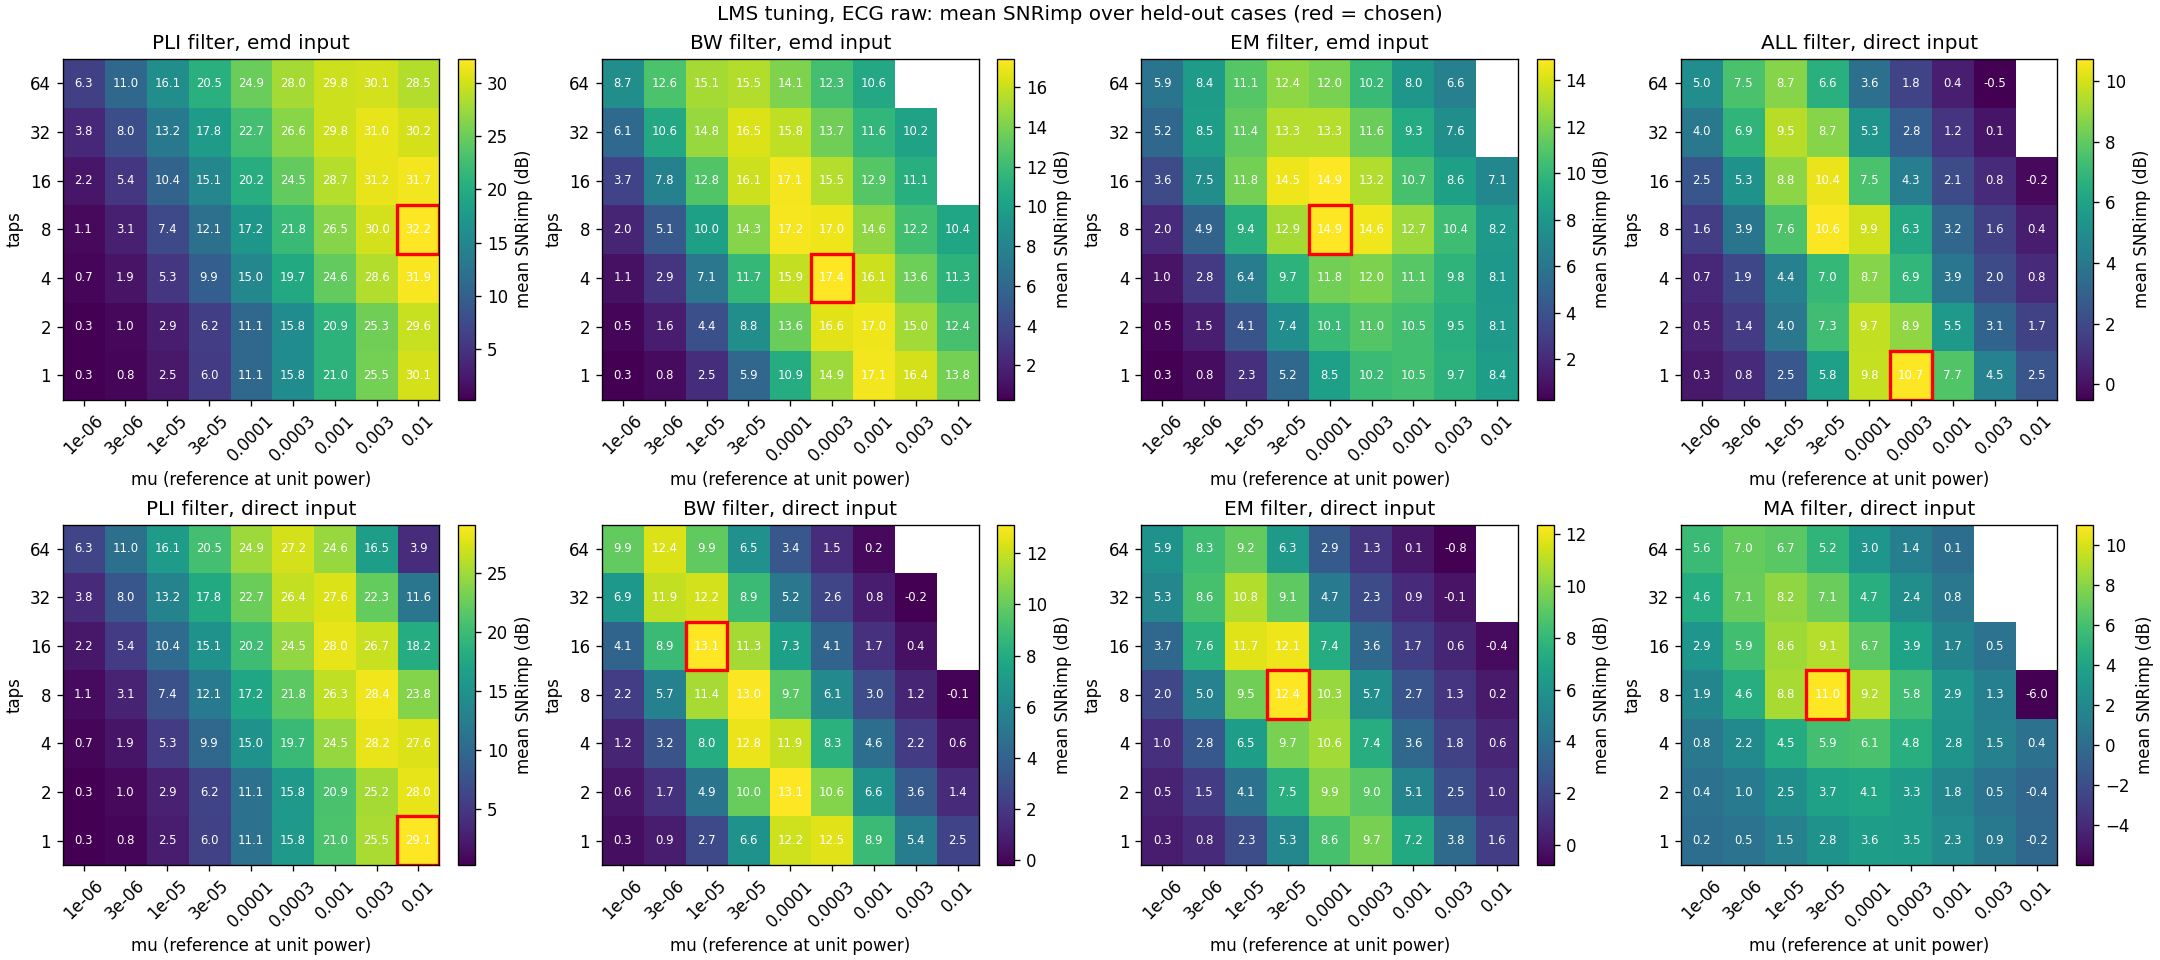

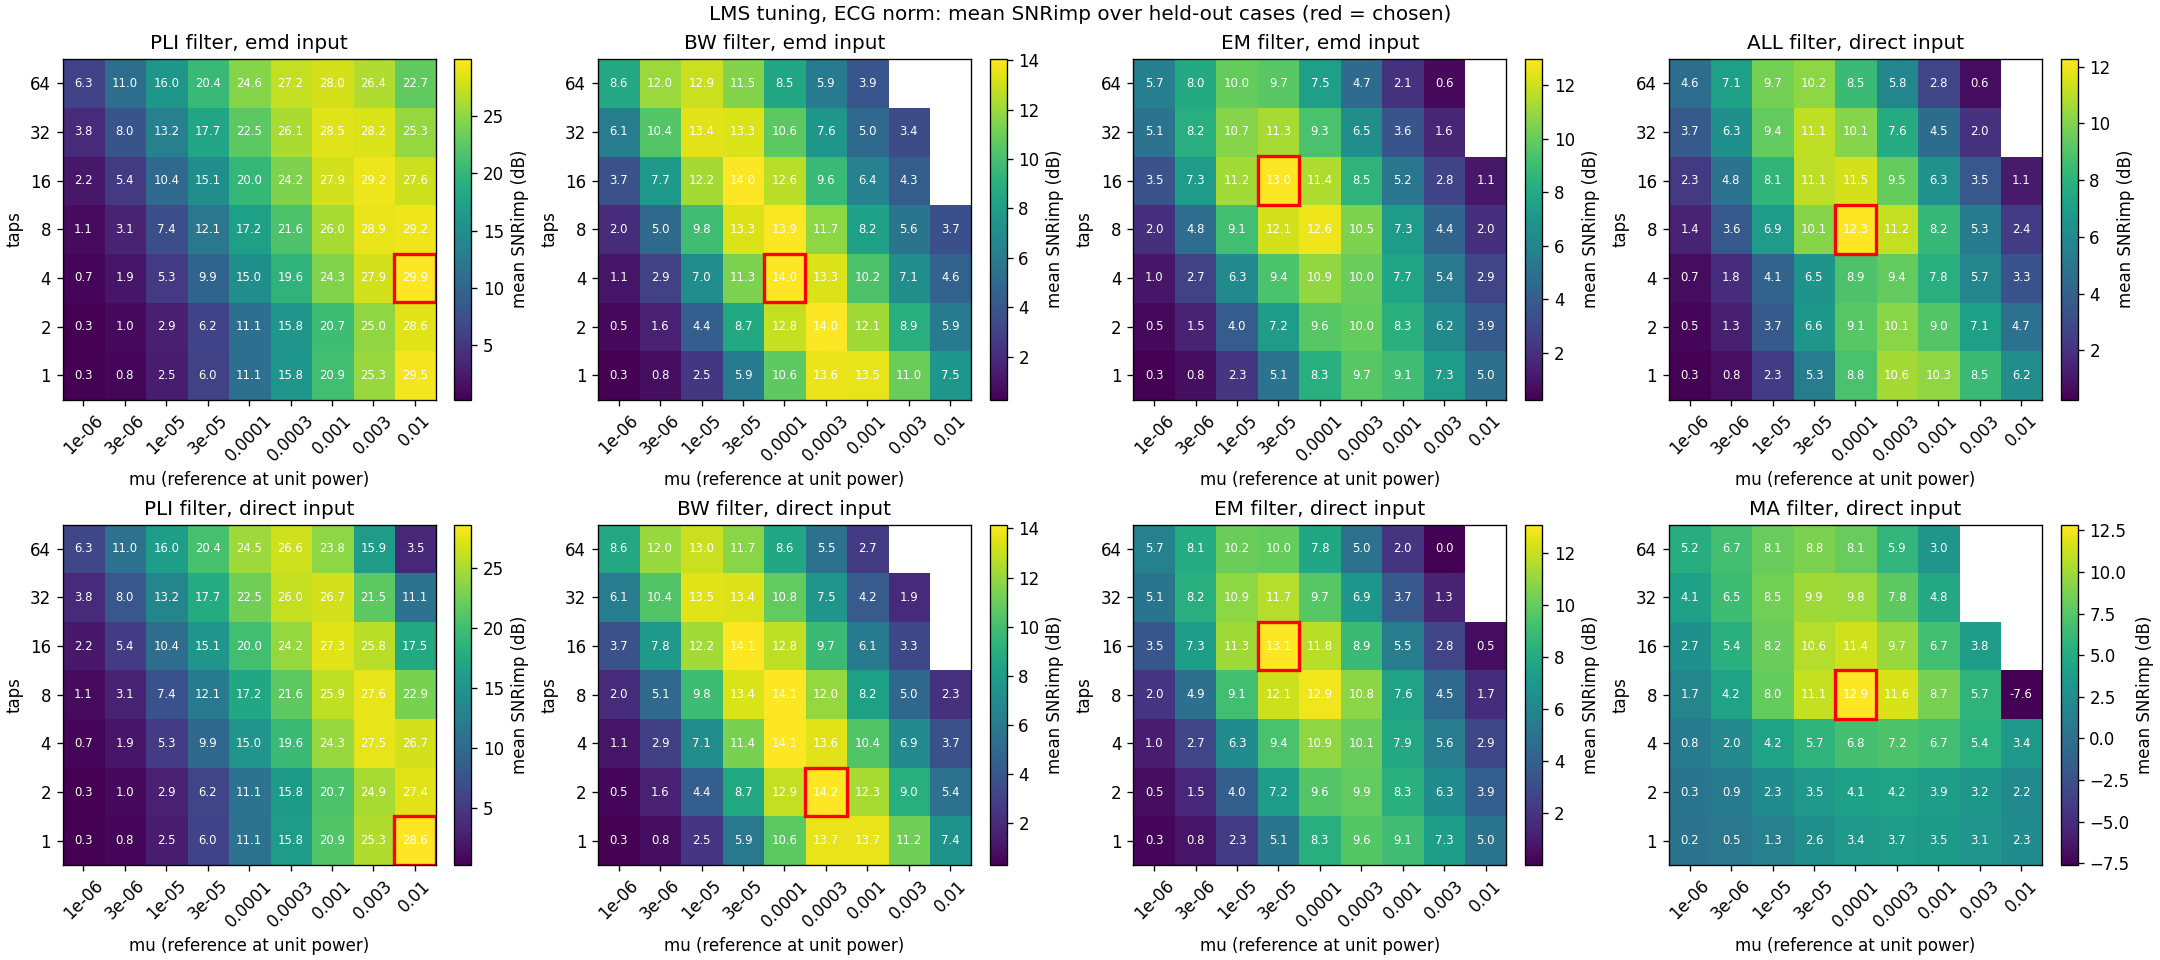

In [3]:
display(Image(FIGURES_DIR / "lms_tuning_raw.png"))
display(Image(FIGURES_DIR / "lms_tuning_norm.png"))

## How the best mu moves with SNRin

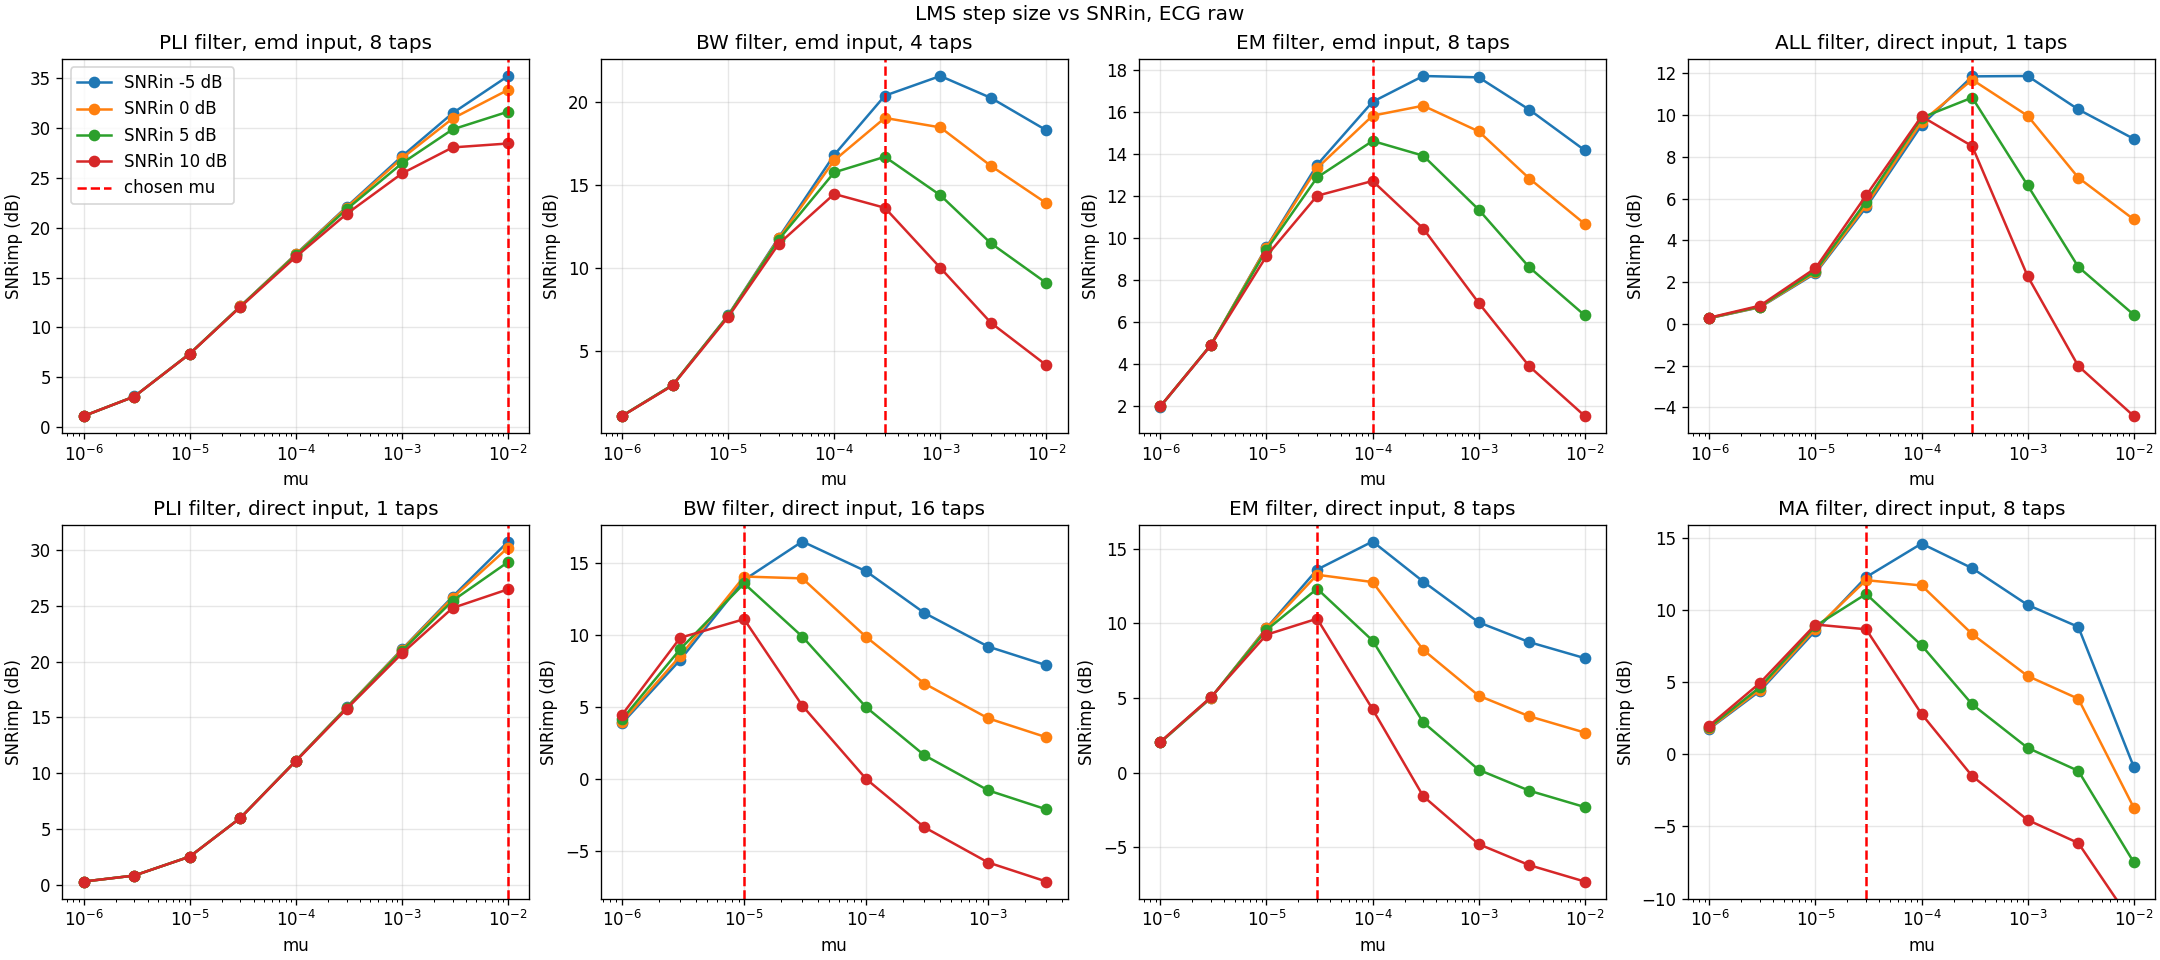

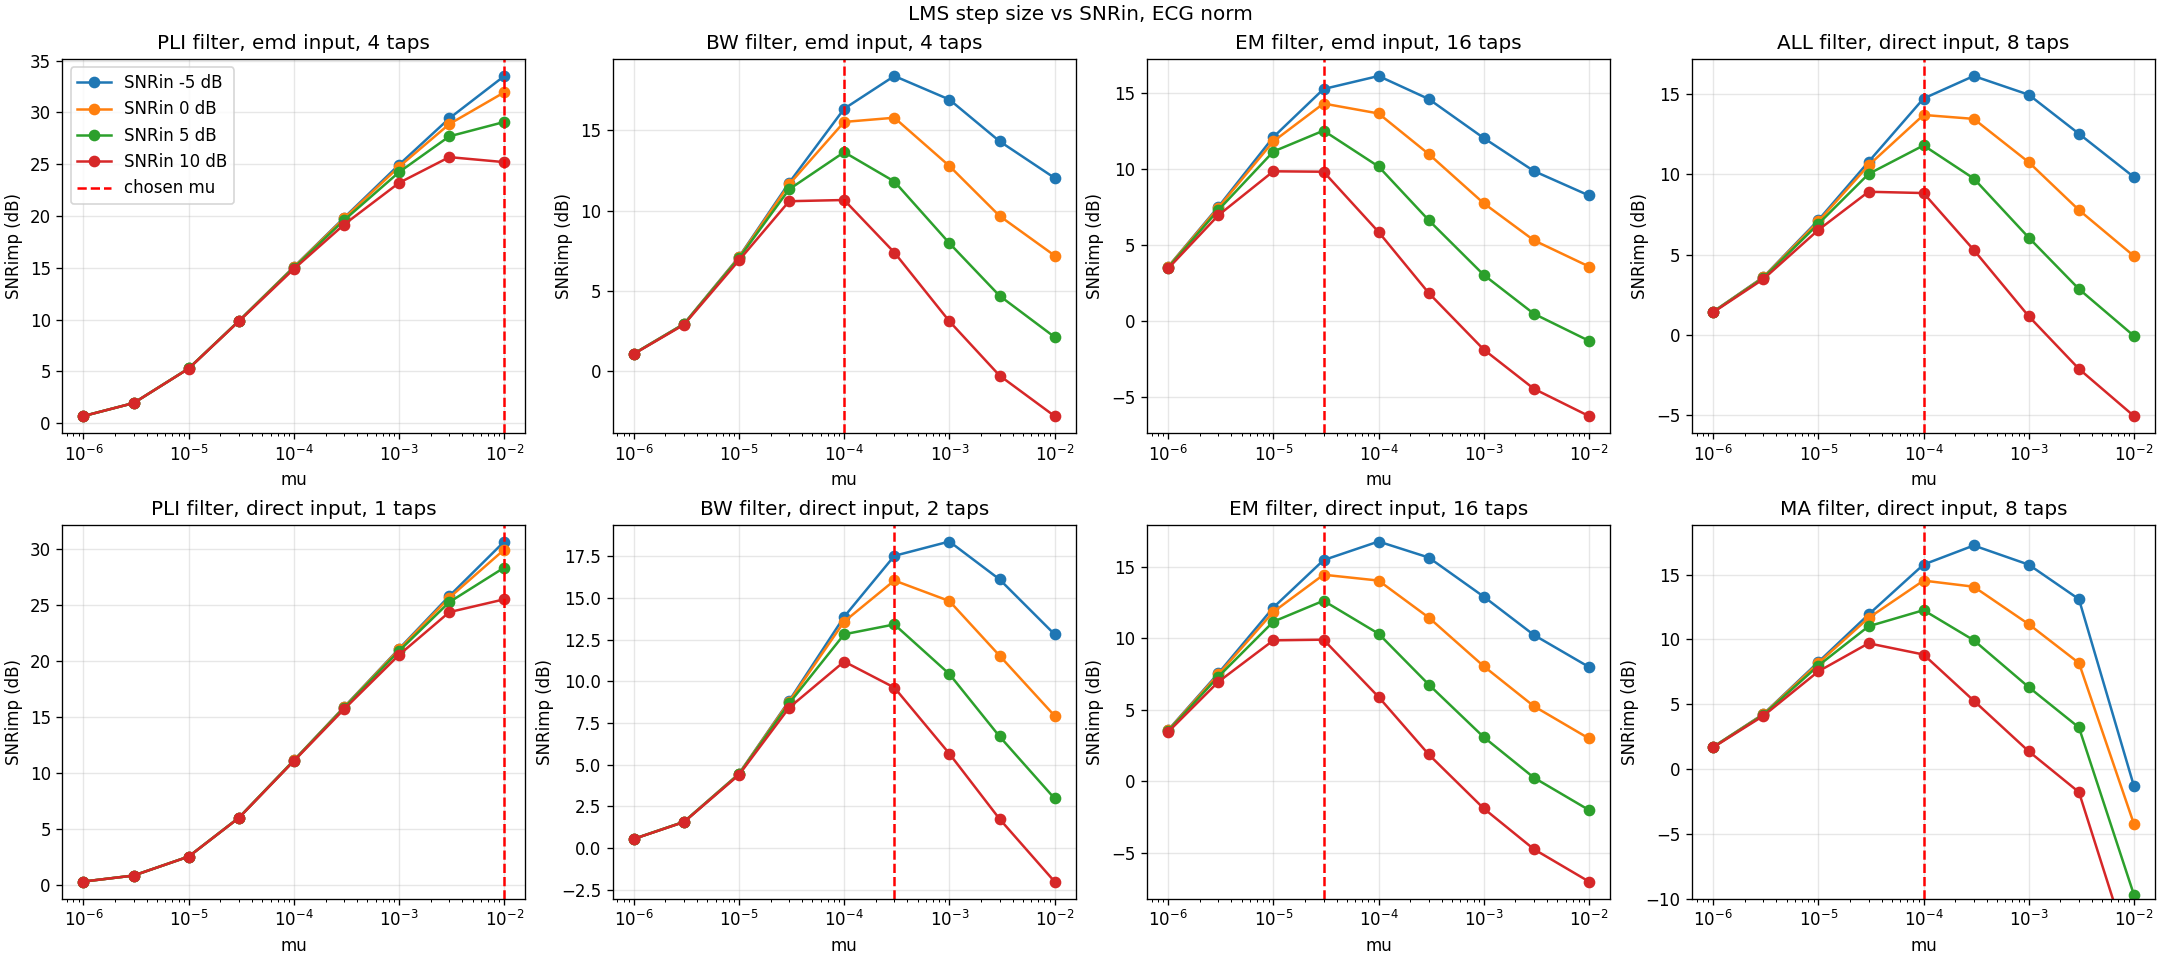

In [4]:
display(Image(FIGURES_DIR / "lms_tuning_vs_snr_raw.png"))
display(Image(FIGURES_DIR / "lms_tuning_vs_snr_norm.png"))